# 02 · Player profiles

The numbers every later analysis reads a player through. The back-test, role discovery and the
similarity search all start from these profiles, so each statistic in them has to describe the
player, not chance or the team around them.

1. **Which numbers describe a player?** The candidate statistics and their definitions, how
   reliable each one is within each comparison group, how much league and team drive it, and
   which ones repeat each other.
2. **How much of it is possession?** How long each team has the ball, how much each statistic
   depends on it, measured within players, and which adjustment takes it out.

**Players:** outfield players of the scouting pool (Premier League, La Liga, Serie A and Ligue 1,
2015/16), compared within the comparison groups of `config/pipeline.yaml`. Carried over from
`01_data_exploration.ipynb`: minutes are real time on the pitch, rates are shrunk by measured
reliability, interceptions, pressures and clearances are compared within recording context, and
xG is StatsBomb's non-penalty xG as published.

**Data:** [StatsBomb Open Data](https://github.com/statsbomb/open-data) (events, lineups) and
Transfermarkt via [dcaribou/transfermarkt-datasets](https://github.com/dcaribou/transfermarkt-datasets)
(dates of birth). Only aggregated results are shown, as StatsBomb's licence requires. Tables are
built by `make model`; see `docs/DATA_DICTIONARY.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter

from football_scouting.analysis.leagues import league_effect, team_effect
from football_scouting.analysis.metrics import (
    FAMILIES,
    LABELS,
    LOWER_IS_BETTER,
    OPEN_PLAY,
    PER_90,
    PROGRESSIVE_RULES,
    SUMMED,
    player_match_counts,
    progressive,
    rates,
)
from football_scouting.analysis.players import pool_player_seasons
from football_scouting.analysis.possession import (
    SIDE,
    adjust_rates,
    elasticity,
    player_possession,
    team_possession,
)
from football_scouting.analysis.reliability import split_half_reliability, stabilisation_minutes
from football_scouting.config import load_config
from football_scouting.model.database import connect_readonly
from football_scouting.plots import GREY, OKABE_ITO, credit, position_colors, use_style

cfg = load_config()
con = connect_readonly(cfg)
use_style()
OUTFIELD = [g.code for g in cfg.comparison_groups if g.code != "GK"]
COLORS = position_colors(cfg)
GROUP_COLORS = {g: COLORS["W" if g == "AMW" else g] for g in OUTFIELD}
GROUP_NAMES = {g.code: g.name for g in cfg.comparison_groups}
LEAGUES = [c.name for c in cfg.statsbomb.competitions if c.scouting_pool]
POOL = "match_id IN (SELECT match_id FROM matches WHERE scouting_pool)"

players = pool_player_seasons(con, cfg, age_on=cfg.backtest.market_view)
counts = player_match_counts(con)
season = rates(counts.groupby("player_id")[SUMMED].sum())
# The team a player spent most minutes with (103 players moved within the pool).
main_team = (
    counts.groupby(["player_id", "team_id"]).minutes.sum().reset_index()
    .sort_values(["minutes", "team_id"]).groupby("player_id").tail(1)
    .set_index("player_id").team_id
)  # fmt: skip
regulars = players[(players.minutes >= 900) & (players.comparison_group != "GK")]
regulars = regulars.set_index("player_id")
group = regulars.comparison_group.astype(str)
print(
    f"{len(players):,} pool players, {len(regulars):,} outfield players with 900+ minutes: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}" for g, n in group.value_counts()[OUTFIELD].items())
    + "."
)

2,176 pool players, 1,266 outfield players with 900+ minutes: centre-backs 261, full-backs 253, central midfielders 307, attacking midfielders and wingers 280, centre-forwards 165.


## 1. Which numbers describe a player?

The exploration measured 15 per-90 rates and a few ratios. A recruitment profile needs more:
how a player moves the ball forward, contests it in the air, presses after losing it, or loses
it. This section lists the candidates, settles the definitions left open (progressive passes and
carries) and tests every candidate three ways, within each comparison group:

- **reliability**: does a season tell players apart, or is it mostly noise?
- **league and team**: does the number describe the player, or where they play?
- **redundancy**: does it say something another number does not?

Reliability is measured on outfield players with 1,800+ minutes (two halves of 900); the other
tests on outfield players with 900+ minutes. Goalkeepers are left out here.

### 1.1 The candidates

46 statistics in seven families, all defined in `analysis.metrics`. Besides the 21 of the
exploration, the candidates are the location-based numbers of its section 6 and:

- **expected assists (xA)**: the xG of the shots a player's open-play passes set up;
- **through balls, switches of play and long passes** (30+ yards), and how often long passes
  and crosses are completed;
- **progressive passes and carries** under three rules, compared in 1.5;
- **aerial duels** and the share won;
- **times dribbled past** per 90, and **dribblers tackled**: tackles won over tackles won plus
  times dribbled past;
- **counterpressures** (pressures within five seconds of the team losing the ball) and
  **pressures in the final third**;
- **ball losses per touch**: miscontrols and dispossessions;
- **fouls won**.

Two of them rest on how StatsBomb records a contest between two players. An aerial duel is
"won" on the winner's action (a pass, clearance, shot or miscontrol flagged `aerial_won`) and
"lost" as a duel event of the loser; a completed dribble leaves a "dribbled past" event for the
defender beaten. Both are checked below.

In [2]:
catalogue = pd.DataFrame(
    {
        "statistics": {f: len(ms) for f, ms in FAMILIES.items()},
        "per 90": {f: sum(m in PER_90 for m in ms) for f, ms in FAMILIES.items()},
        "ratios": {f: sum(m not in PER_90 for m in ms) for f, ms in FAMILIES.items()},
        "members": {f: "; ".join(LABELS[m] for m in ms) for f, ms in FAMILIES.items()},
    }
)
catalogue.loc["All"] = [*catalogue.iloc[:, :3].sum(), ""]
with pd.option_context("display.max_colwidth", None):
    display(catalogue)

aerials = counts.groupby("match_id")[["aerials_won", "aerials_lost"]].sum()
dribbles_beaten = con.sql(f"""
    WITH done AS (
        SELECT match_id, competition_id, match_seconds, team_id FROM dribbles
        WHERE {POOL} AND outcome = 'Complete'),
    past AS (
        SELECT competition_id, count(*) AS dribbled_past FROM dribbled_past
        WHERE {POOL} GROUP BY ALL)
    SELECT competition_id, count(*) AS completed,
           avg(EXISTS (SELECT 1 FROM dribbled_past p
                       WHERE p.match_id = done.match_id AND p.team_id <> done.team_id
                         AND abs(p.match_seconds - done.match_seconds) <= 2)::INT) AS beaten,
           any_value(past.dribbled_past) / count(*) AS per_dribble
    FROM done JOIN past USING (competition_id) GROUP BY competition_id
""").df()
print(
    f"Aerial duels: won = lost in {(aerials.aerials_won == aerials.aerials_lost).sum():,} of "
    f"{len(aerials):,} matches ({aerials.aerials_won.sum():,} each)."
)
done = dribbles_beaten.completed
print(
    "Completed dribbles with a 'dribbled past' event of the other team within 2 seconds: "
    f"{(dribbles_beaten.beaten * done).sum() / done.sum():.1%} of {done.sum():,}; "
    "'dribbled past' events per completed dribble: "
    f"{dribbles_beaten.per_dribble.min():.2f} to {dribbles_beaten.per_dribble.max():.2f} by league."
)

,statistics,per 90,ratios,members
Shooting,7,5,2,Non-penalty shots; Non-penalty xG; Non-penalty goals; Non-penalty xG per shot; Finishing: non-penalty goals minus xG per shot; Touches in the opposition box; Passes received in the box
Chance creation,6,5,1,"Key passes (open play); Expected assists (xA, open play); Completed passes into the box; Through balls; Open-play crosses; Cross completion"
Passing and progression,9,7,2,Open-play passes; Open-play pass completion; Long passes (30+ yards); Long pass completion; Switches of play; Completed passes into the final third; Progressive passes (10 yards); Progressive passes (zones); Progressive passes (25% closer)
Carrying and ball security,9,7,2,Dribbles attempted; Dribble success; Carries into the final third; Carries into the box; Progressive carries (10 yards); Progressive carries (zones); Progressive carries (25% closer); Fouls won; Ball losses per touch
Defending,10,9,1,Pressures; Counterpressures; Pressures in the final third; Tackles; Dribblers tackled; Times dribbled past; Interceptions; Ball recoveries; Clearances; Blocks
Aerial duels,2,1,1,Aerial duels; Aerial duels won
Position,3,0,3,"Average touch position (x, towards goal); Average touch distance from the centre line; Height of defensive actions (x)"
All,46,34,12,


Aerial duels: won = lost in 1,517 of 1,517 matches (64,925 each).
Completed dribbles with a 'dribbled past' event of the other team within 2 seconds: 100.0% of 29,079; 'dribbled past' events per completed dribble: 1.09 to 1.11 by league.


### 1.2 Reliability within each comparison group

The exploration measured reliability over all outfield players, rates centred within group and
league (section 2 of `01_data_exploration.ipynb`). A profile compares players within one group,
so here reliability is also measured within each group: the same 50 random split halves, rates
centred within league. The number is the correlation between two halves of 900 minutes, which
is the share of the spread between players at 900 minutes that is real. A statistic enters a
profile at 0.4 or more; shrinkage then pulls the noisy part towards the group average.

In [3]:
METRICS = [m for ms in FAMILIES.values() for m in ms]
GRID = [180, 270, 360, 450, 600, 750, 900]

long_season = players[(players.minutes >= 1800) & (players.comparison_group != "GK")]
long_group = long_season.comparison_group.astype(str)
curve = split_half_reliability(
    counts[counts.player_id.isin(long_season.player_id)],
    (long_group + " | " + long_season.league).set_axis(long_season.player_id),
    METRICS,
    GRID,
)
K = stabilisation_minutes(curve, METRICS)
r900 = {"All outfield": curve[curve.target == 900][METRICS].mean()}
used = {"All outfield": curve[curve.target == 900].players.mean()}
for g in OUTFIELD:
    sub = long_season[long_group == g]
    by_group = split_half_reliability(
        counts[counts.player_id.isin(sub.player_id)],
        sub.league.set_axis(sub.player_id),
        METRICS,
        [900],
    )
    r900[g], used[g] = by_group[METRICS].mean(), by_group.players.mean()
r900 = pd.DataFrame(r900)
print(
    "Players with 900 minutes in both halves (mean of 50 draws): "
    + ", ".join(f"{GROUP_NAMES.get(g, g).lower()} {n:.0f}" for g, n in used.items())
    + "."
)

Players with 900 minutes in both halves (mean of 50 draws): all outfield 702, centre-backs 172, full-backs 137, central midfielders 186, attacking midfielders and wingers 127, centre-forwards 79.


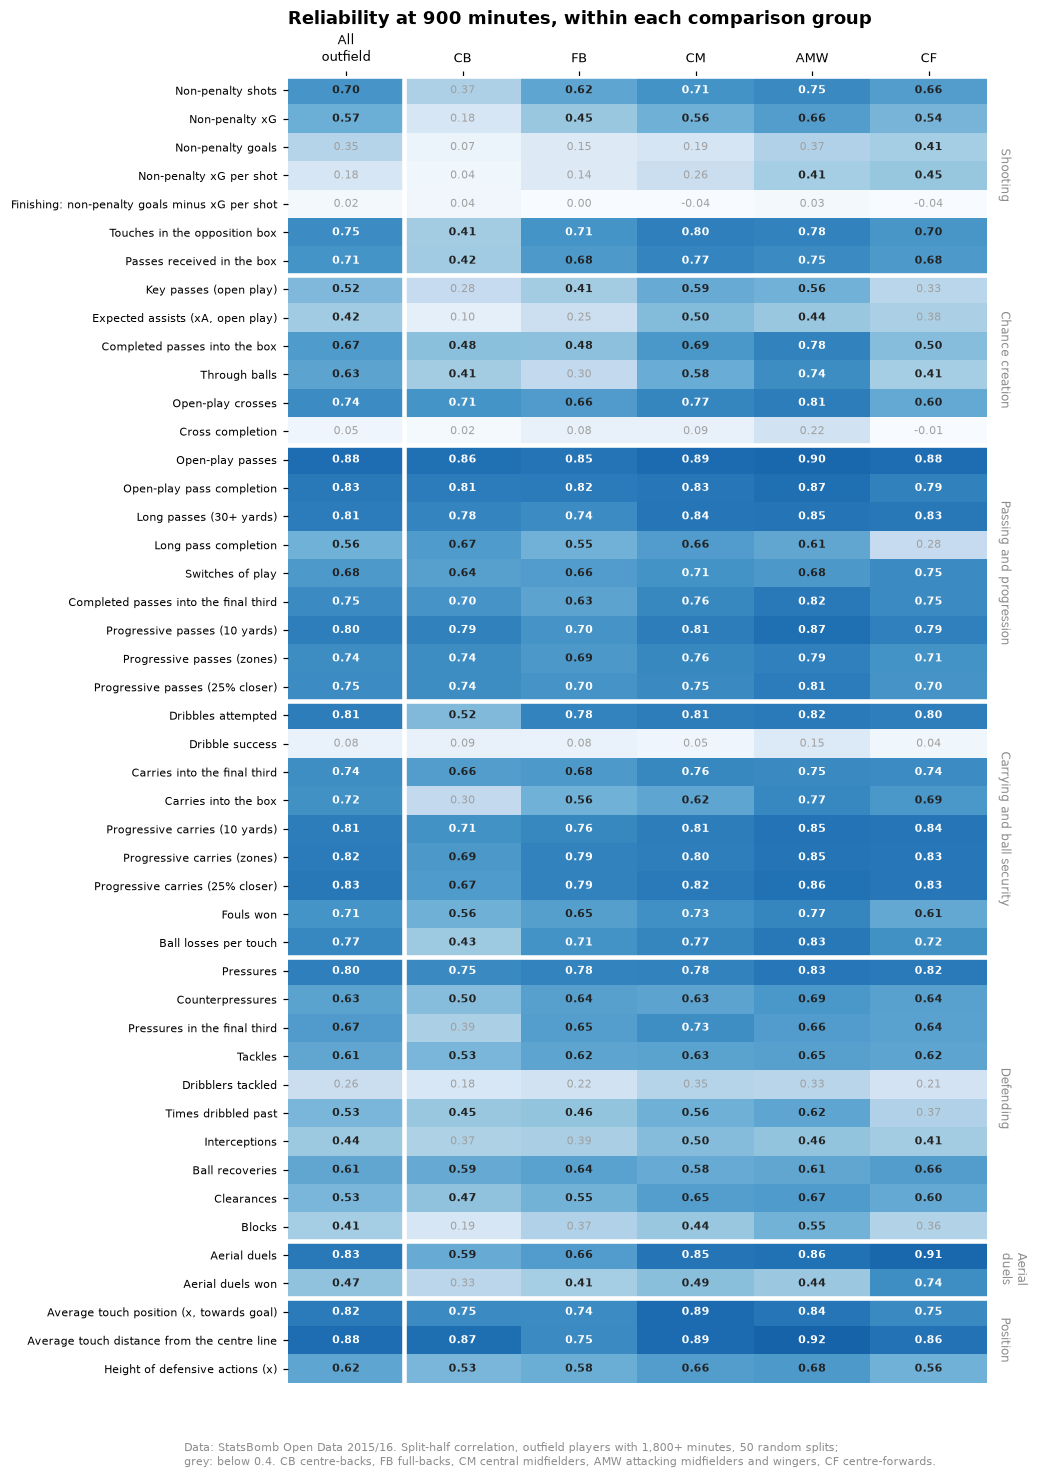

In [4]:
COLUMNS = ["All outfield", *OUTFIELD]
fig, ax = plt.subplots(figsize=(8.2, 13.2))
shown = r900.loc[METRICS, COLUMNS]
ax.imshow(shown.clip(lower=0), cmap="Blues", vmin=0, vmax=1.15, aspect="auto")
for (i, j), v in np.ndenumerate(shown.to_numpy()):
    ax.text(
        j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
        color="white" if v >= 0.7 else ("#222222" if v >= 0.4 else "#A0A0A0"),
        fontweight="bold" if v >= 0.4 else "normal",
    )  # fmt: skip
ax.set_xticks(range(len(COLUMNS)), ["All\noutfield", *OUTFIELD], fontsize=8.5)
ax.xaxis.tick_top()
ax.set_yticks(range(len(METRICS)), [LABELS[m] for m in METRICS], fontsize=7.5)
start = 0
for family, members in FAMILIES.items():
    ax.axhline(start - 0.5, color="white", lw=3)
    ax.text(
        len(COLUMNS) - 0.4, start + len(members) / 2 - 0.5,
        family if len(members) > 3 else family.replace(" ", "\n"), rotation=-90,
        ha="left", va="center", fontsize=8, color=GREY,
    )  # fmt: skip
    start += len(members)
ax.axvline(0.5, color="white", lw=3)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Reliability at 900 minutes, within each comparison group", pad=34)
fig.subplots_adjust(top=0.92, bottom=0.02)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Split-half correlation, outfield players with 1,800+ "
    "minutes, 50 random splits;\ngrey: below 0.4. CB centre-backs, FB full-backs, CM central "
    "midfielders, AMW attacking midfielders and wingers, CF centre-forwards.",
)
plt.show()

In [5]:
# Minutes at which a rate is half signal, half noise: K = 900 (1 - r) / r within each group.
k_by_group = (900 * (1 - r900[OUTFIELD]) / r900[OUTFIELD]).where(r900[OUTFIELD] > 0)
EXAMPLES = [
    "passes", "xg", "key_passes", "xa", "interceptions", "aerial_win_rate",
    "long_pass_completion", "carries_into_box",
]  # fmt: skip
k_table = pd.concat([K.rename("All outfield (curve fit)"), k_by_group], axis=1).loc[EXAMPLES]
k_table.index = [LABELS[m] for m in EXAMPLES]
reliable = r900[OUTFIELD].ge(0.4)
print(
    "Statistics at 0.4 or more: "
    + ", ".join(f"{g} {n}" for g, n in reliable.sum().items())
    + f" of {len(METRICS)}; below 0.4 in every group: "
    + ", ".join(LABELS[m] for m in r900.index[~reliable.any(axis=1)])
    + "."
)
k_table.round(-1).astype("Int64")

Statistics at 0.4 or more: CB 31, FB 36, CM 40, AMW 41, CF 37 of 46; below 0.4 in every group: Finishing: non-penalty goals minus xG per shot, Cross completion, Dribble success, Dribblers tackled.


,All outfield (curve fit),CB,FB,CM,AMW,CF
Open-play passes,130,140,160,110,100,120
Non-penalty xG,720,4000,1110,690,470,760
Key passes (open play),890,2260,1290,630,720,1820
"Expected assists (xA, open play)",1350,8140,2700,890,1140,1450
Interceptions,1240,1540,1410,890,1060,1300
Aerial duels won,1080,1850,1320,940,1160,320
Long pass completion,790,440,720,460,570,2260
Carries into the box,360,2100,710,560,270,410


### 1.3 League and team

The exploration found attacking and passing numbers on one scale across the four leagues
(league partial η² of 0.03 or less), and three defensive numbers recorded differently between
leagues or, in the Premier League, from 28 December 2015 (match week 19). The same tests for the
candidates, on players with 900+ minutes: the league's partial η² within comparison group, each
league's gap from the group average, and the change from match week 19 in team-match totals (the
second part of the season over the first), in the Premier League and at most in another league.
Shown: the statistics above 0.03, or whose rate per 90 changes by more than 10%.

In [6]:
d = season.loc[regulars.index].assign(
    league=regulars.league, group=group, team=main_team.reindex(regulars.index)
)
league_table = pd.DataFrame({m: league_effect(d, m) for m in METRICS}).T

weeks = con.sql("SELECT match_id, match_week >= 19 AS late FROM matches").df()
team_matches = (
    counts.groupby(["match_id", "competition_id", "team_id"])[SUMMED].sum().reset_index()
    .merge(weeks, on="match_id")
)  # fmt: skip
halves = team_matches.groupby(["competition_id", "late"])[SUMMED].sum()
half_rates = rates(halves)
shift = half_rates.xs(True, level="late") / half_rates.xs(False, level="late")
PL_ID = next(c.competition_id for c in cfg.statsbomb.competitions if c.name == "Premier League")
league_table["Premier League from week 19"] = shift.loc[PL_ID] - 1
league_table["largest elsewhere"] = (
    (shift.drop(index=PL_ID) - 1).abs().max().reindex(league_table.index)
)
# Changes are read on per-90 rates (finishing, for one, sits around zero).
changed = league_table.index.isin(list(PER_90)) & (
    league_table["Premier League from week 19"].abs() > 0.10
)
flagged = league_table[(league_table["partial η²"] > 0.03) | changed]
flagged = flagged.sort_values("partial η²", ascending=False)
flagged.index = [LABELS[m] for m in flagged.index]
FORMATS = {
    "partial η²": "{:.3f}", **dict.fromkeys(LEAGUES, "{:+.0f}%"),
    "Premier League from week 19": "{:+.0%}", "largest elsewhere": "±{:.0%}",
}  # fmt: skip
flagged.apply(lambda col: col.map(FORMATS[col.name].format))

,partial η²,La Liga,Ligue 1,Premier League,Serie A,Premier League from week 19,largest elsewhere
Interceptions,0.245,+37%,-10%,-7%,-20%,+189%,±8%
Pressures,0.080,-6%,+7%,-8%,+7%,+18%,±7%
Clearances,0.080,-7%,-3%,+19%,-7%,+16%,±2%
Pressures in the final third,0.080,-8%,+7%,-12%,+12%,+21%,±7%
Fouls won,0.063,+6%,-1%,-18%,+13%,-2%,±6%
Times dribbled past,0.061,+13%,-8%,+9%,-13%,-4%,±4%
"Average touch position (x, towards goal)",0.046,-1%,-2%,+1%,+2%,+1%,±1%
Dribblers tackled,0.044,-4%,+6%,-4%,+1%,-0%,±2%
Counterpressures,0.042,-3%,+7%,-9%,+4%,+14%,±6%


In [7]:
LEAGUE_OF = {c.competition_id: c.name for c in cfg.statsbomb.competitions}
by_league = counts.groupby("competition_id")
per_match = (
    by_league[["fouls_won", "dribbles_completed", "dribbled_past"]].sum()
    .div(by_league.match_id.nunique(), axis=0) / 2
)  # fmt: skip
per_match.index = per_match.index.map(LEAGUE_OF)
per_match.columns = ["Fouls won", "Completed dribbles", "Times dribbled past"]
per_match.rename_axis("Per team and match").round(1)

,Fouls won,Completed dribbles,Times dribbled past
Per team and match,,,
Premier League,12.0,10.6,11.5
Ligue 1,14.0,8.8,9.8
La Liga,15.2,10.6,11.6
Serie A,15.9,8.4,9.2


**Fouls won** and **times dribbled past** are new to the list, and neither is a recording
artefact. Fouls won follow the refereeing: Serie A matches have a third more fouls than Premier
League matches, so the same player draws more fouls in Italy. Times dribbled past follow the
opposition: every completed dribble leaves a "dribbled past" event, and Premier League and La
Liga teams complete more dribbles per match. In both, the league gap is about the league, not
the player. **Counterpressures** and **pressures in the final third** are pressures, and change
with them in the Premier League from match week 19; they fall under the rule already set for
pressures (compared within recording context).

The team matters more than the league. With one to three players per team and group, teams
"explain" about 7% of any number by chance alone, so the share below is adjusted for it, as R²
is for the number of predictors. The team includes its league.

In [8]:
team_table = pd.Series({m: team_effect(d, m) for m in METRICS}, name="team share")
top = team_table.sort_values(ascending=False).head(12)
print(
    f"Median over the {len(METRICS)} statistics: {team_table.median():.2f}; "
    f"below 0.05: {(team_table < 0.05).sum()}."
)
top.rename(index=LABELS).round(2).to_frame()

Median over the 46 statistics: 0.08; below 0.05: 11.


,team share
Open-play passes,0.48
Open-play pass completion,0.38
Interceptions,0.26
Long pass completion,0.23
Progressive passes (10 yards),0.21
Height of defensive actions (x),0.21
Touches in the opposition box,0.19
"Average touch position (x, towards goal)",0.18
Clearances,0.18
Through balls,0.18


Passing volume and pass completion depend most on the team: a player passes as often, and as
safely, as the team keeps the ball. Interceptions follow, through the league's recording. How
much of this is possession, and whether it should be adjusted for, is the subject of section 2.

### 1.4 Redundancy

Two statistics that rank a group's players the same way take two slots in a profile to say one
thing. For each group, Spearman correlations between the statistics reliable in that group
(0.4 or more), on players with 900+ minutes. Below: every pair at 0.8 or more in at least one
group, with the correlation in each group where both are reliable. Goals, finishing and dribble
success are left out: the exploration found them mostly noise and they do not rank players.

In [9]:
NOT_RANKED = ["goals", "finishing", "dribble_success"]
pairs = {}
for g in OUTFIELD:
    ok = [m for m in METRICS if r900.loc[m, g] >= 0.4 and m not in NOT_RANKED]
    rho = d.loc[group == g, ok].corr("spearman")
    for i, a in enumerate(ok):
        for b in ok[i + 1 :]:
            pairs.setdefault((a, b), {})[g] = rho.loc[a, b]
pairs = pd.DataFrame(pairs).T.reindex(columns=OUTFIELD)
close = pairs[pairs.abs().ge(0.8).any(axis=1)]
close = close.loc[close.abs().max(axis=1).sort_values(ascending=False).index]
close.index = [f"{LABELS[a]} ~ {LABELS[b]}" for a, b in close.index]
print(f"{len(close)} pairs at 0.8 or more in at least one group.")
close.map(lambda v: "" if pd.isna(v) else f"{v:.2f}")

22 pairs at 0.8 or more in at least one group.


,CB,FB,CM,AMW,CF
Progressive carries (zones) ~ Progressive carries (25% closer),0.95,0.98,0.98,0.98,0.97
Progressive passes (zones) ~ Progressive passes (25% closer),0.98,0.96,0.97,0.95,0.91
Touches in the opposition box ~ Passes received in the box,0.95,0.94,0.96,0.89,0.87
Progressive carries (10 yards) ~ Progressive carries (zones),0.92,0.94,0.96,0.94,0.96
Progressive carries (10 yards) ~ Progressive carries (25% closer),0.89,0.92,0.94,0.92,0.95
Completed passes into the final third ~ Progressive passes (10 yards),0.81,0.89,0.93,0.93,0.85
Carries into the final third ~ Progressive carries (10 yards),0.77,0.93,0.89,0.87,0.89
Carries into the final third ~ Progressive carries (zones),0.75,0.93,0.88,0.86,0.89
Carries into the final third ~ Progressive carries (25% closer),0.71,0.89,0.87,0.83,0.85
Open-play passes ~ Progressive passes (10 yards),0.84,0.77,0.85,0.87,0.71


Three kinds of overlap. The rules for progressive passes, and for progressive carries, rank
players much the same way (1.5 picks one). Passes into the final third repeat progressive
passes, carries into the final third repeat progressive carries, and passes received in the box
repeat touches in the box, in almost every group. The rest meet in one or two groups, mostly
among central midfielders: pass completion and long pass completion, key passes and xA, long
passes and switches, shots, xG and touches in the box, pressures and counterpressures.

### 1.5 Progressive passes and carries

A progressive pass or carry moves the ball substantially towards the opponent's goal. The
definition varies by provider; three common rules were tested on completed open-play passes and
on carries:

- **10 yards**: at least 10 yards towards the goal line, passes starting beyond the defending
  40% of the pitch and carries ending in the other half (FBref's rule, without its reference to
  the previous six passes);
- **zones**: at least 30 m closer to the centre of the goal within the own half, 15 m from the
  own half into the other, 10 m within the other half (Wyscout's rule, on a 105 m pitch);
- **25% closer**: ending at least 25% closer to the centre of the goal.

The rules differ in where they count. The figure shows, by where the ball starts, the share of
passes and carries each rule counts.

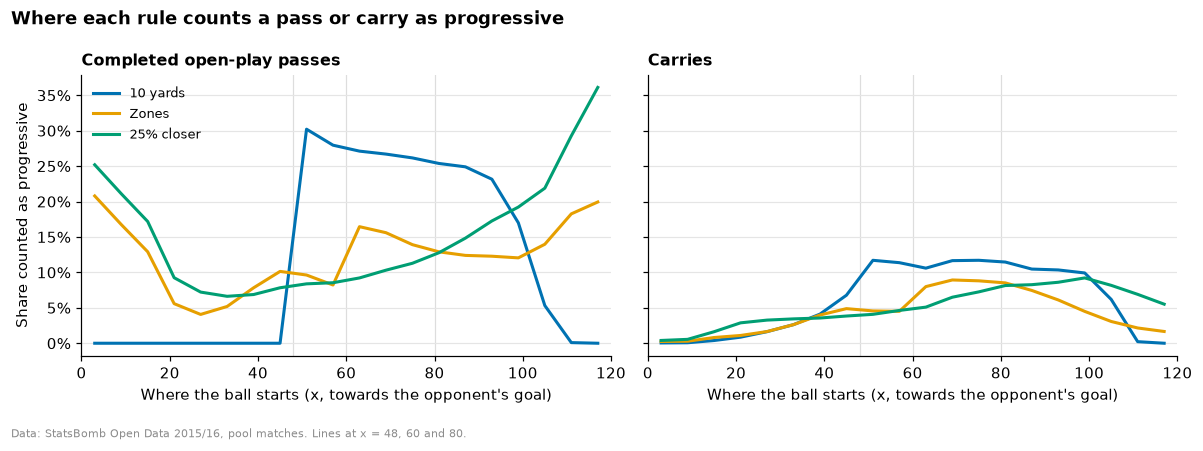

In [10]:
BINS = 6  # units along the pitch
where_counted = {}
for kind, table, extra in [("pass", "passes", f"AND {OPEN_PLAY} AND completed"),
                           ("carry", "carries", "")]:  # fmt: skip
    rules = ", ".join(f'avg({progressive(r, kind)}::INT) AS "{r}"' for r in PROGRESSIVE_RULES)
    where_counted[kind] = con.sql(f"""
        SELECT least(floor(x / {BINS}) * {BINS} + {BINS} / 2, 117) AS x, count(*) AS n, {rules}
        FROM {table} WHERE {POOL} {extra} GROUP BY 1 ORDER BY 1
    """).df()

RULE_NAMES = {"10y": "10 yards", "zones": "Zones", "25pct": "25% closer"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (kind, title) in zip(
    axes, [("pass", "Completed open-play passes"), ("carry", "Carries")], strict=True
):
    w = where_counted[kind]
    for colour, rule in zip(OKABE_ITO, PROGRESSIVE_RULES, strict=False):
        ax.plot(w.x, w[rule], color=colour, lw=2, label=RULE_NAMES[rule])
    for edge in (48, 60, 80):
        ax.axvline(edge, color="#DDDDDD", lw=0.8, zorder=0)
    ax.set_xlim(0, 120)
    ax.set_xlabel("Where the ball starts (x, towards the opponent's goal)")
    ax.set_title(title, fontsize=10.5)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("Share counted as progressive")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle(
    "Where each rule counts a pass or carry as progressive", x=0.01, ha="left",
    fontweight="bold", fontsize=12,
)  # fmt: skip
credit(fig, "Data: StatsBomb Open Data 2015/16, pool matches. Lines at x = 48, 60 and 80.")
fig.tight_layout()
plt.show()

In [11]:
def summary(prefix: str, volume: str) -> pd.DataFrame:
    rows = {}
    for rule in PROGRESSIVE_RULES:
        m = f"{prefix}_{rule}"
        within = {g: d.loc[group == g, [m, volume, f"{prefix}_zones"]].corr("spearman")
                  for g in OUTFIELD}  # fmt: skip
        rows[RULE_NAMES[rule]] = {
            "per 90, median player": d[m].median(),
            "reliability, lowest group": r900.loc[m, OUTFIELD].min(),
            "reliability, highest group": r900.loc[m, OUTFIELD].max(),
            "team share": team_table[m],
            f"Spearman with {LABELS[volume].lower()}": np.median(
                [c.loc[m, volume] for c in within.values()]
            ),
            "Spearman with zones": np.median(
                [c.loc[m, f"{prefix}_zones"] for c in within.values()]
            ),
        }
    return pd.DataFrame(rows).T


print("Progressive passes (Spearman: median over the five groups)")
display(summary("progressive_passes", "passes").round(2))
print("Progressive carries")
display(summary("progressive_carries", "dribbles").round(2))

Progressive passes (Spearman: median over the five groups)


,"per 90, median player","reliability, lowest group","reliability, highest group",team share,Spearman with open-play passes,Spearman with zones
10 yards,4.76,0.70,0.87,0.21,0.84,0.79
Zones,3.14,0.69,0.79,0.08,0.60,1.00
25% closer,3.04,0.70,0.81,0.09,0.62,0.96


Progressive carries


,"per 90, median player","reliability, lowest group","reliability, highest group",team share,Spearman with dribbles attempted,Spearman with zones
10 yards,2.38,0.71,0.85,0.08,0.7,0.94
Zones,1.40,0.69,0.85,0.07,0.7,1.00
25% closer,1.39,0.67,0.86,0.08,0.7,0.98


The 10-yard rule ignores the defending 40% of the pitch and, beyond it, counts a quarter to a
third of all passes, since most forward passes in midfield cover 10 yards; near the goal, 10
yards forward is no longer possible. So it mostly counts passes: it is the most reliable, but it
ranks players by passing volume (Spearman 0.84 with open-play passes) and depends most on the
team (0.21). Zones and 25% closer count long passes from deep, ask more in midfield, and keep
counting near the goal. The two rank players almost the same way (0.91 to 0.98), keep most of
the reliability, and depend far less on the team (0.08 and 0.09) and on passing volume (0.60 and
0.62). For carries the three rules agree closely in every group.

**Zones** is the rule kept, for passes and carries: it measures progress rather than volume, it
is a standard in the industry (Wyscout), and it treats passes and carries alike. 25% closer
would do as well.

### 1.6 The profiles

Each comparison group's profile takes up to 12 statistics:

- reliable within the group (0.4 or more at 900 minutes);
- not goals, finishing or dribble success (mostly noise; exploration, sections 2 and 5);
- no two at a Spearman correlation of 0.8 or more within the group: of a pair, the more
  reliable or the one a scout reads more directly stays;
- covering the families each group's role calls for. For attackers, xG per 90 comes with shot
  volume and shot quality (as set in the exploration, section 5); position descriptors (touch position, width,
  height of defensive actions) describe a role, not how well it is played, and are kept for role
  discovery;
- fouls won and times dribbled past stay out: the first measures the league's refereeing as much
  as the player, the second the opposition's dribbling, and dribblers tackled, its fair version,
  is noise in every group.

The lists are kept in `config/pipeline.yaml` (`profiles`).

In [12]:
# Kept in config/pipeline.yaml (`profiles`), which every later notebook reads.
PROFILES = {g: list(statistics) for g, statistics in cfg.profiles.items()}


def profile_check(g: str) -> dict:
    ms = PROFILES[g]
    rho = d.loc[group == g, ms].corr("spearman").abs().to_numpy()
    np.fill_diagonal(rho, np.nan)
    return {
        "statistics": len(ms),
        "lowest reliability": r900.loc[ms, g].min(),
        "highest Spearman between two": np.nanmax(rho),
        "families": len({f for f, members in FAMILIES.items() for m in ms if m in members}),
    }


pd.DataFrame({GROUP_NAMES[g]: profile_check(g) for g in OUTFIELD}).T.round(2)

,statistics,lowest reliability,highest Spearman between two,families
Centre-backs,12.0,0.43,0.73,4.0
Full-backs,12.0,0.41,0.76,5.0
Central midfielders,12.0,0.50,0.69,5.0
Attacking midfielders and wingers,12.0,0.41,0.72,5.0
Centre-forwards,12.0,0.45,0.65,6.0


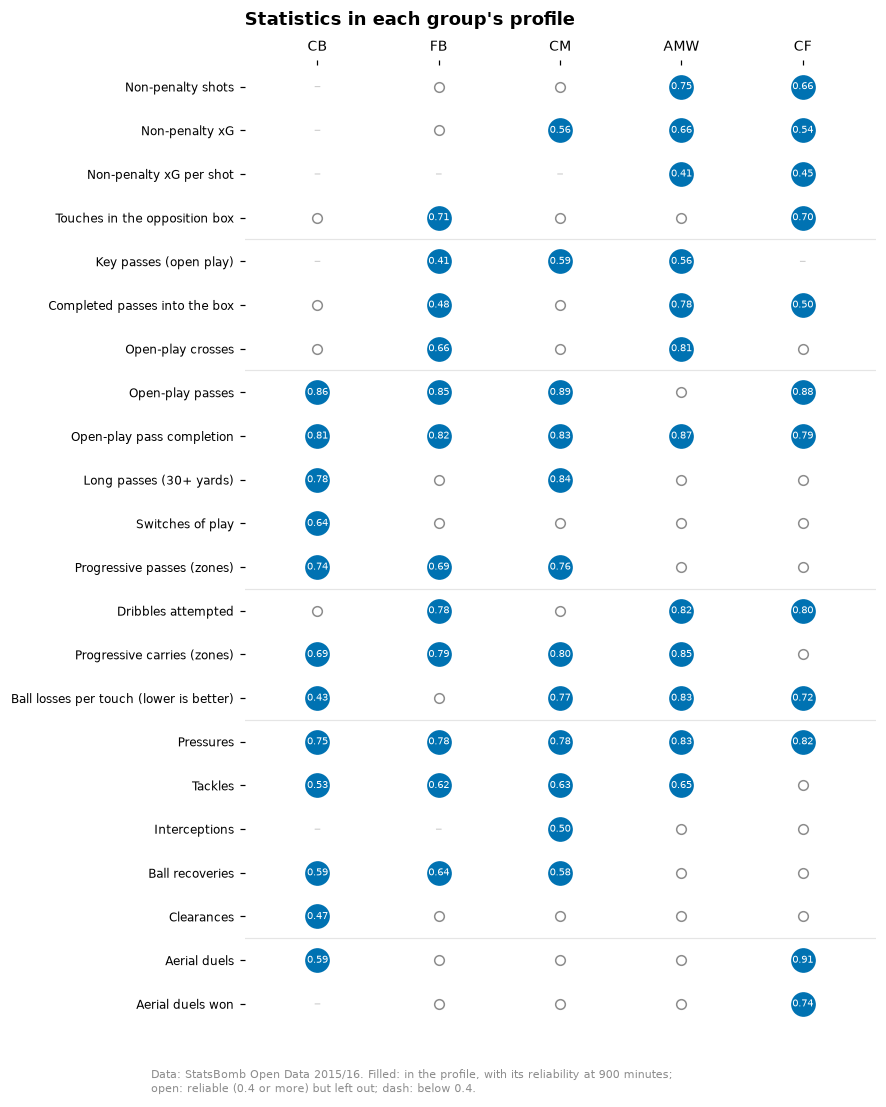

In [13]:
in_any = [m for m in METRICS if any(m in ms for ms in PROFILES.values())]
fig, ax = plt.subplots(figsize=(7.4, 9.6))
for j, g in enumerate(OUTFIELD):
    for i, m in enumerate(in_any):
        r = r900.loc[m, g]
        if m in PROFILES[g]:
            ax.scatter(j, i, s=230, color=OKABE_ITO[0], zorder=3)
            ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6.5, color="white",
                    zorder=4)  # fmt: skip
        elif r >= 0.4:
            ax.scatter(j, i, s=40, facecolor="white", edgecolor=GREY, lw=1, zorder=3)
        else:
            ax.text(j, i, "–", ha="center", va="center", fontsize=9, color="#C8C8C8")
labels = [LABELS[m] + (" (lower is better)" if m in LOWER_IS_BETTER else "") for m in in_any]
ax.set_yticks(range(len(in_any)), labels, fontsize=8)
ax.set_xticks(range(len(OUTFIELD)), OUTFIELD, fontsize=9)
ax.xaxis.tick_top()
ax.set_ylim(len(in_any) - 0.5, -0.5)
ax.set_xlim(-0.6, len(OUTFIELD) - 0.4)
start = 0
for members in FAMILIES.values():
    n = sum(m in in_any for m in members)
    if n and start:
        ax.axhline(start - 0.5, color="#E5E5E5", lw=0.8)
    start += n
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Statistics in each group's profile", pad=26)
fig.subplots_adjust(top=0.93, bottom=0.02)
credit(
    fig,
    "Data: StatsBomb Open Data 2015/16. Filled: in the profile, with its reliability at 900 "
    "minutes;\nopen: reliable (0.4 or more) but left out; dash: below 0.4.",
)
plt.show()

### What section 1 shows

- **Candidates.** 46 statistics in seven families. StatsBomb's records of contests hold up:
  aerial duels won equal aerial duels lost in every match, and every completed dribble leaves a
  "dribbled past" event for the defender.
- **Reliability depends on the group.** The same statistic can be signal in one group and noise
  in another: xG per 90 is 0.66 among attacking midfielders and wingers but 0.18 among
  centre-backs; the share of aerial duels won is 0.74 among centre-forwards but 0.33 among
  centre-backs, whose shares sit close together (half of them between 61% and 70%). Interceptions and blocks fall below 0.4 for
  centre-backs. Cross completion, dribble success, dribblers tackled and finishing are noise in
  every group. Each group's rates are therefore shrunk with the group's own K.
- **League and team.** Fouls won (refereeing) and times dribbled past (opposition) carry league
  gaps that are not about the player. Counterpressures and pressures in the final third change
  with the Premier League's recording, like pressures. The team weighs more than the league on
  passing volume and pass completion, the starting point of section 2.
- **Progressive actions** follow Wyscout's zones: a measure of progress rather than passing
  volume, depending less than half as much on the team as the 10-yard rule.
- **Profiles.** 12 statistics per group, each reliable in its group, no pair correlated at 0.8
  or more, covering what the role does.

## 2. How much of it is possession?

Section 1 found the team behind much of a player's passing. The first suspect is possession: a
player can only pass while the team has the ball, and only tackle while the opponent has it. A
centre-back at a team with two thirds of the ball has more passes to make than one at a team
that defends for most of the match, whatever their ability. This section measures each team's
possession, how much each profile statistic depends on it, and compares ways to take it out.
How a team uses the ball beyond how long it keeps it (how high it presses, how directly it
plays) is a matter of style, described in the team-style analysis, not adjusted here.

### 2.1 Measuring possession

Possession is measured as time with the ball. The time from each event to the next, within a
half, goes to the team in possession (StatsBomb's possession team, which the opponent's
pressures and tackles also carry), with gaps capped at 10 seconds so that stoppages count
little. A player's possession is the team's share of that time **while the player is on the
pitch**: a substitute who comes on at 0-1 plays a different match from the starter they
replace.

In [14]:
team_poss = team_possession(con)
player_poss = player_possession(con)
counts_poss = counts.merge(player_poss, on=["match_id", "team_id", "player_id"], how="left")

clock = con.sql(
    "SELECT match_id, player_id, on_seconds, off_seconds, match_end_seconds, seconds_played "
    "FROM player_matches WHERE played"
).df()
whole = counts_poss.merge(clock, on=["match_id", "player_id"]).query(
    "on_seconds == 0 and off_seconds == match_end_seconds"
)
whole = whole.merge(team_poss, on=["match_id", "team_id"])
team_passes = counts.groupby(["match_id", "team_id"]).passes.sum()
by_match = team_poss.join(team_passes, on=["match_id", "team_id"])
by_match["pass_share"] = by_match.passes / by_match.groupby("match_id").passes.transform("sum")
on_pitch = counts_poss.merge(clock, on=["match_id", "player_id"])
print(
    f"Players on the pitch for a whole match ({len(whole):,}): their own time with the ball "
    f"equals their team's in {np.isclose(whole.own_seconds, whole.seconds).mean():.1%}.\n"
    "Time credited to one team or the other: "
    f"{(on_pitch.own_seconds + on_pitch.opp_seconds).sum() / on_pitch.seconds_played.sum():.0%} of "
    "the time on the pitch.\n"
    "A team's share of a match: correlation with its share of open-play passes "
    f"{by_match[['share', 'pass_share']].corr().iloc[0, 1]:.3f}; from "
    f"{by_match.share.min():.0%} to {by_match.share.max():.0%}, 90% between "
    f"{by_match.share.quantile(0.05):.0%} and {by_match.share.quantile(0.95):.0%}."
)

Players on the pitch for a whole match (24,300): their own time with the ball equals their team's in 100.0%.
Time credited to one team or the other: 75% of the time on the pitch.
A team's share of a match: correlation with its share of open-play passes 0.966; from 22% to 78%, 90% between 35% and 65%.


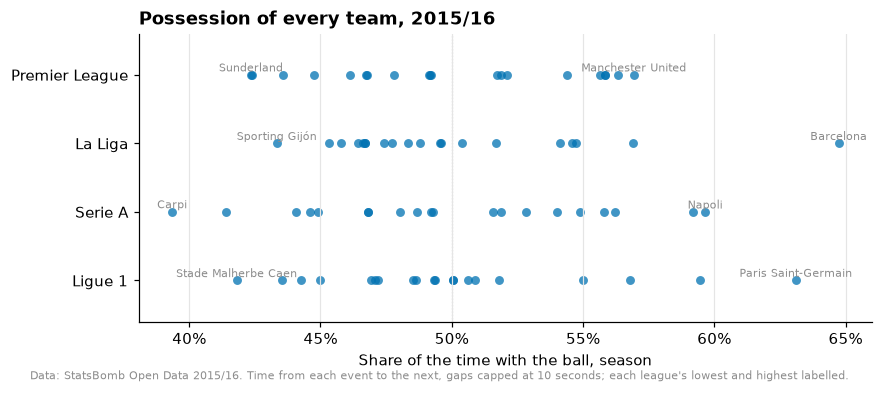

In [15]:
TEAM_NAMES = con.sql("SELECT team_id, team_name FROM teams").df().set_index("team_id").team_name
LEAGUE_OF_MATCH = (
    con.sql(f"SELECT match_id, competition_id FROM matches WHERE {POOL}")
    .df()
    .set_index("match_id")
    .competition_id.map({c.competition_id: c.name for c in cfg.statsbomb.competitions})
)
team_poss["opp_seconds"] = (
    team_poss.groupby("match_id").seconds.transform("sum") - team_poss.seconds
)
team_season = team_poss.groupby("team_id")[["seconds", "opp_seconds"]].sum()
team_season["share"] = team_season.seconds / (team_season.seconds + team_season.opp_seconds)
team_season["league"] = (
    team_poss.drop_duplicates("team_id").set_index("team_id").match_id.map(LEAGUE_OF_MATCH)
)

fig, ax = plt.subplots(figsize=(8.6, 3.4))
for i, league in enumerate(LEAGUES):
    teams = team_season[team_season.league == league].sort_values("share")
    ax.scatter(teams.share, np.full(len(teams), i), s=34, color=OKABE_ITO[0], alpha=0.75, lw=0)
    for team_id, va, dy in [(teams.index[0], "top", -0.18), (teams.index[-1], "top", -0.18)]:
        ax.text(teams.share[team_id], i + dy, TEAM_NAMES[team_id], fontsize=7.5, color=GREY,
                ha="center", va=va)  # fmt: skip
ax.axvline(0.5, color="#BBBBBB", lw=0.8, ls=":", zorder=0)
ax.set_yticks(range(len(LEAGUES)), LEAGUES)
ax.set_ylim(len(LEAGUES) - 0.4, -0.6)
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of the time with the ball, season")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_title("Possession of every team, 2015/16")
credit(fig, "Data: StatsBomb Open Data 2015/16. Time from each event to the next, gaps capped "
       "at 10 seconds; each league's lowest and highest labelled.")  # fmt: skip
plt.show()

Time with the ball and the share of passes tell the same story match by match. The lowest and
highest team of each league are about 20 points apart, 15 in the Premier League: Barcelona
(65%) and Paris Saint-Germain (63%) have the ball most, Carpi (39%) least.

### 2.2 Possession and the profile statistics, season by season

For every outfield player with 900+ minutes, the correlation (Spearman) between each profile
statistic and the player's possession share, within the comparison group. Rates are taken
relative to the group's average in the player's league, so that league and recording
differences do not count. Blank: not in the group's profile.

In [16]:
reg_sums = counts_poss.groupby("player_id")[[*SUMMED, "own_seconds", "opp_seconds"]].sum()
share = (reg_sums.own_seconds / (reg_sums.own_seconds + reg_sums.opp_seconds)).loc[regulars.index]
league = regulars.league
PROFILE_STATS = [m for m in METRICS if any(m in ms for ms in PROFILES.values())]


def relative(values: pd.Series) -> pd.Series:
    """Rates over the average of the player's comparison group and league."""
    keys = [group.reindex(values.index), league.reindex(values.index)]
    return values / values.groupby(keys).transform("mean")


def with_possession(values: pd.Series, g: str) -> float:
    rel = relative(values)[group == g]
    return rel.corr(share[group == g], method="spearman")


season_corr = pd.DataFrame(
    {
        g: {m: with_possession(season.loc[regulars.index, m], g) for m in PROFILES[g]}
        for g in OUTFIELD
    }
).loc[PROFILE_STATS]
shown = season_corr.copy()
shown.index = [LABELS[m] + ("" if m in PER_90 else " (ratio)") for m in PROFILE_STATS]
shown.map(lambda v: "" if pd.isna(v) else f"{v:+.2f}")

,CB,FB,CM,AMW,CF
Non-penalty shots,,,,+0.31,+0.34
Non-penalty xG,,,+0.14,+0.38,+0.39
Non-penalty xG per shot (ratio),,,,+0.20,+0.18
Touches in the opposition box,,+0.38,,,+0.40
Key passes (open play),,+0.34,+0.30,+0.40,
Completed passes into the box,,+0.34,,+0.33,+0.33
Open-play crosses,,+0.30,,-0.01,
Open-play passes,+0.84,+0.78,+0.74,,+0.30
Open-play pass completion (ratio),+0.72,+0.65,+0.60,+0.44,+0.35
Long passes (30+ yards),+0.38,,+0.31,,


The statistics made with the ball go with possession: open-play passes most of all (0.74 to
0.84 among defenders and central midfielders), and pass completion with them. The defensive
counts barely do (pressures -0.07 to -0.21, tackles -0.16 to +0.07), except centre-backs'
clearances (-0.37) and ball recoveries (+0.35): a team with less of the ball gives its players
more to defend, but over a season they do not tackle or press more for it. Season figures mix
two things, though: the time a team has the ball, and the players a team with the ball can
afford. Better teams have more of the ball **and** better players, and a season correlation
cannot tell the two apart.

### 2.3 How much a count depends on possession, within players

The same player's matches can: when a team has more or less of the ball than usual, the
player is the same. For each comparison group and per-90 statistic, a Poisson regression of
the player's count in each match on the log of the share of possession on the statistic's side
(the team's own share for actions with the ball, the opponent's for actions without it), with
minutes on the pitch as exposure and a fixed effect per player, fitted by its conditional
likelihood so that only differences within a player count (`possession.elasticity`). The slope
is an **elasticity**: 1 means the count grows in proportion to the time on its side, 0 that it
does not depend on it. Aerial duels are contested by both teams and listed without the ball.
Players with 900+ minutes, all their matches; standard errors are clustered by player.

In [17]:
WITH_BALL = [m for m in PER_90 if SIDE[m] == "with"]
reg_counts = counts_poss[counts_poss.player_id.isin(regulars.index)].assign(
    group=lambda x: x.player_id.map(group)
)
reg_counts["with"] = reg_counts.own_seconds / (reg_counts.own_seconds + reg_counts.opp_seconds)
reg_counts["without"] = 1 - reg_counts["with"]
# Robustness: the share without the player's own time on the ball, and matches of 45+ minutes.
own_rest = reg_counts.own_seconds - reg_counts.self_own_seconds
opp_rest = reg_counts.opp_seconds - reg_counts.self_opp_seconds
reg_counts["with_rest"] = own_rest / (own_rest + opp_rest)
reg_counts["without_rest"] = 1 - reg_counts["with_rest"]

rows = []
for g in OUTFIELD:
    sub = reg_counts[reg_counts.group == g]
    for m in PER_90:
        beta, se = elasticity(sub, m, SIDE[m])
        rows.append({
            "group": g, "metric": m, "beta": beta, "se": se,
            "without own time": elasticity(sub, m, SIDE[m] + "_rest")[0],
            "45+ minutes": elasticity(sub[sub.minutes >= 45], m, SIDE[m])[0],
        })  # fmt: skip
elasticities = pd.DataFrame(rows)
BETA = elasticities.pivot(index="metric", columns="group", values="beta")[OUTFIELD]
for check in ["without own time", "45+ minutes"]:
    change = elasticities[check] - elasticities.beta
    print(
        f"{check}: elasticities change by a median of {round(change.median(), 2) + 0:+.2f} "
        f"(largest {change.abs().max():.2f}) over {len(change)} statistic-group pairs."
    )

without own time: elasticities change by a median of -0.05 (largest 0.20) over 170 statistic-group pairs.
45+ minutes: elasticities change by a median of +0.00 (largest 0.17) over 170 statistic-group pairs.


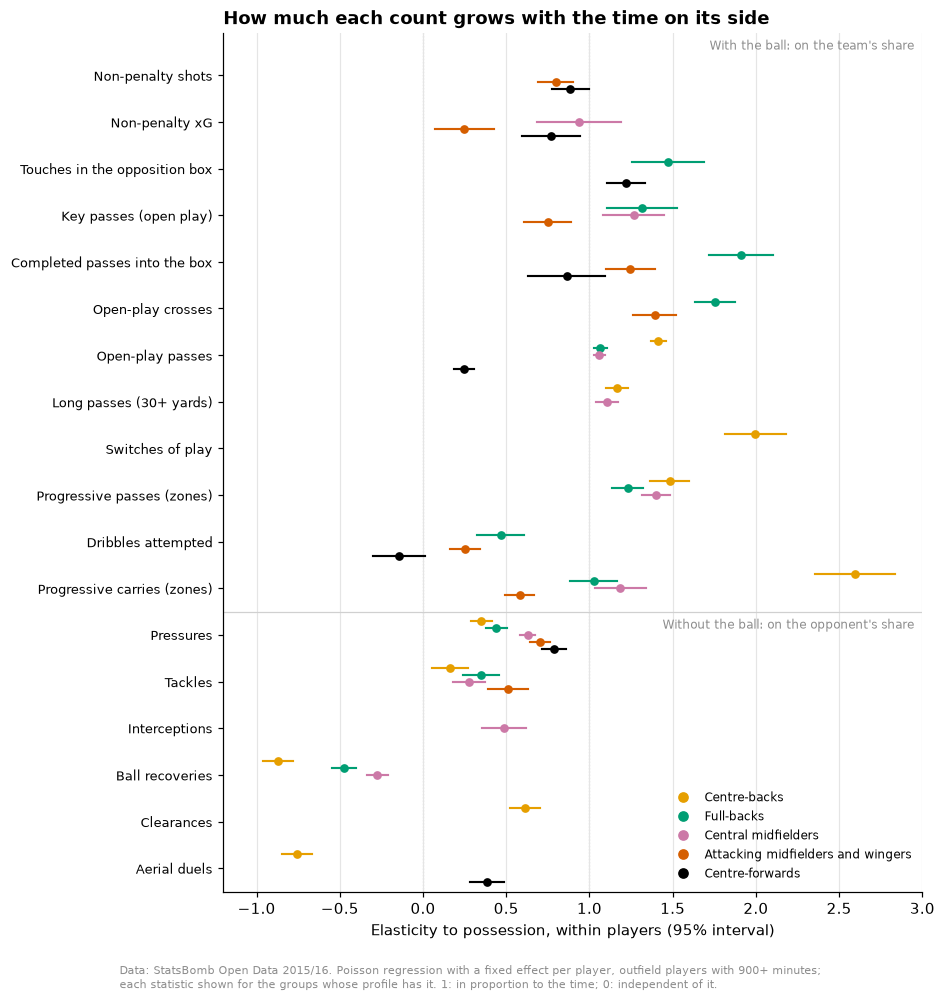

In [18]:
SIDE_ORDER = [m for m in PROFILE_STATS if m in PER_90 and SIDE[m] == "with"] + [
    m for m in PROFILE_STATS if m in PER_90 and SIDE[m] == "without"
]
est = elasticities.set_index(["metric", "group"])
fig, ax = plt.subplots(figsize=(8.2, 9.4))
offsets = dict(zip(OUTFIELD, np.linspace(-0.3, 0.3, len(OUTFIELD)), strict=True))
for i, m in enumerate(SIDE_ORDER):
    for g in OUTFIELD:
        if m not in PROFILES[g]:
            continue
        beta, se = est.loc[(m, g), ["beta", "se"]]
        y = i + offsets[g]
        ax.plot([beta - 1.96 * se, beta + 1.96 * se], [y, y], color=GROUP_COLORS[g], lw=1.4)
        ax.scatter(beta, y, s=22, color=GROUP_COLORS[g], zorder=3)
for x in (0, 1):
    ax.axvline(x, color="#BBBBBB", lw=0.8, ls=":", zorder=0)
n_with = sum(SIDE[m] == "with" for m in SIDE_ORDER)
ax.axhline(n_with - 0.5, color="#D0D0D0", lw=0.8)
ax.text(2.95, -0.55, "With the ball: on the team's share", fontsize=8, color=GREY, ha="right")
ax.text(2.95, n_with - 0.35, "Without the ball: on the opponent's share", fontsize=8,
        color=GREY, ha="right", va="top")  # fmt: skip
ax.set_yticks(range(len(SIDE_ORDER)), [LABELS[m] for m in SIDE_ORDER], fontsize=8.5)
ax.set_ylim(len(SIDE_ORDER) - 0.5, -0.9)
ax.set_xlim(-1.2, 3.0)
ax.set_xlabel("Elasticity to possession, within players (95% interval)")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.legend(
    handles=[plt.Line2D([], [], marker="o", ls="", color=GROUP_COLORS[g], label=GROUP_NAMES[g])
             for g in OUTFIELD],
    loc="lower right", fontsize=8,
)  # fmt: skip
ax.set_title("How much each count grows with the time on its side")
fig.subplots_adjust(bottom=0.05)
credit(fig, "Data: StatsBomb Open Data 2015/16. Poisson regression with a fixed effect per "
       "player, outfield players with 900+ minutes;\neach statistic shown for the groups whose "
       "profile has it. 1: in proportion to the time; 0: independent of it.")  # fmt: skip
plt.show()

**With the ball, most counts grow faster than the time.** A defender's or central midfielder's
passes rise about in proportion (elasticity 1.06 to 1.41), and the actions that move the ball
forward or into the box faster still: progressive passes 1.23 to 1.48, full-backs' passes into
the box 1.91, centre-backs' switches 2.00 and progressive carries 2.60. A team with more of the
ball also has it higher up the pitch, against an opponent sitting deeper. Forwards are the
exception: a centre-forward's passes (0.25) and dribbles, and an attacking midfielder's or
winger's xG (0.25) and dribbles (0.25), barely depend on how much of the ball the team has.

**Without the ball, counts grow more slowly than the opponent's time**: pressures 0.35 to 0.79,
tackles 0.16 to 0.51, clearances 0.61, interceptions 0.49. Ball recoveries (-0.27 to -0.87) and
centre-backs' aerial duels (-0.76) go the other way: they rise when the team has more of the
ball, from loose balls and long clearances of an opponent pinned back. Leaving the player's own
time on the ball out of the share, or keeping only matches of 45 minutes or more, changes the
elasticities little.

### 2.4 Four ways to adjust

Each per-90 statistic in a profile is put on an even share of possession in four ways:

- **none**: the rate as recorded;
- **in proportion to the time** on the statistic's side: the rate per 90 minutes of 50%
  possession, rate x 0.5 / share (elasticity 1);
- **PAdj**, StatsBomb's possession adjustment of defensive counts (Knutson, 2014), applied to
  the statistics without the ball: rate x 2 / (1 + exp(-0.1 (possession - 50))), with the
  team's possession while the player is on the pitch, in %;
- **measured elasticity**: rate x (0.5 / share)^elasticity, with each group's elasticity from
  2.3.

Ratios (pass completion, ball losses per touch, xG per shot, aerial duels won) are rates per
action, not per minute: possession gives them no extra chances and they are left as recorded.
Each adjustment is judged on three things, within each comparison group: what is left of the
correlation with possession, how much the team explains (adjusted for chance, as in 1.3), and
the reliability at 900 minutes (the same 50 split halves as in 1.2, the adjustment applied to
each half).

In [19]:
def padj(rate, own_share):
    """StatsBomb's possession-adjusted defensive counts (Knutson, 2014)."""
    return rate * 2 / (1 + np.exp(-0.1 * (100 * own_share - 50)))


ADJUSTMENTS = ["none", "proportional", "PAdj", "elasticity"]


def adjusted(r: pd.DataFrame, own_share: pd.Series, g: str, how: str) -> pd.DataFrame:
    """Per-90 rates of one comparison group's profile, adjusted for possession."""
    stats = [m for m in PROFILES[g] if m in PER_90]
    if how == "proportional":
        return adjust_rates(r, own_share, dict.fromkeys(stats, 1.0))
    if how == "elasticity":
        return adjust_rates(r, own_share, BETA.loc[stats, g])
    out = r.copy()
    if how == "PAdj":
        for m in stats:
            if SIDE[m] == "without":
                out[m] = padj(out[m], own_share)
    return out


reg_rates = season.loc[regulars.index]
long_season_ids = set(long_season.player_id)
POSS_COLUMNS = [*SUMMED, "own_seconds", "opp_seconds"]
rows = []
for g in OUTFIELD:
    ids = group.index[group == g]
    sub = long_season[long_group == g]
    for how in ADJUSTMENTS:
        values = adjusted(reg_rates.loc[ids], share.loc[ids], g, how)
        frame = values.assign(team=main_team.reindex(ids), group=g)
        reliability = split_half_reliability(
            counts_poss[counts_poss.player_id.isin(sub.player_id)],
            sub.league.set_axis(sub.player_id),
            PROFILES[g],
            [900],
            columns=POSS_COLUMNS,
            rate_fn=lambda s, g=g, how=how: adjusted(
                rates(s), s.own_seconds / (s.own_seconds + s.opp_seconds), g, how
            ),
        )[PROFILES[g]].mean()
        for m in PROFILES[g]:
            frame[m] = relative(values[m])
            rows.append({
                "group": g, "metric": m, "adjustment": how,
                "with possession": frame[m].corr(share.loc[ids], method="spearman"),
                "team share": team_effect(frame, m),
                "reliability": reliability[m],
                "same order": values[m].corr(reg_rates.loc[ids, m], method="spearman"),
            })  # fmt: skip
compared = pd.DataFrame(rows)
compared["side"] = compared.metric.map(lambda m: SIDE.get(m, "ratio"))

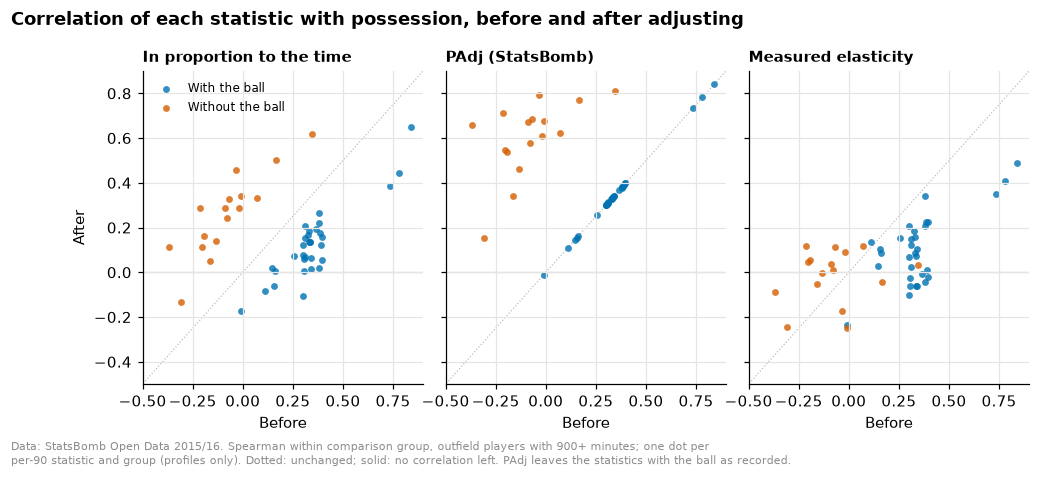

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(10.4, 3.9), sharex=True, sharey=True)
raw = compared[compared.adjustment == "none"].set_index(["group", "metric"])["with possession"]
SIDE_COLORS = {"with": OKABE_ITO[0], "without": OKABE_ITO[5]}
for ax, how, title in zip(
    axes, ADJUSTMENTS[1:], ["In proportion to the time", "PAdj (StatsBomb)", "Measured elasticity"],
    strict=True,
):  # fmt: skip
    sub = compared[(compared.adjustment == how) & (compared.side != "ratio")]
    for side, colour in SIDE_COLORS.items():
        s = sub[sub.side == side]
        ax.scatter(raw.loc[list(zip(s.group, s.metric, strict=True))], s["with possession"],
                   s=20, color=colour, alpha=0.8, lw=0,
                   label=f"{side} the ball".capitalize())  # fmt: skip
    ax.plot([-1, 1], [-1, 1], color="#BBBBBB", lw=0.8, ls=":", zorder=0)
    ax.axhline(0, color="#BBBBBB", lw=0.8, zorder=0)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Before")
    ax.grid(axis="x")
axes[0].set_ylabel("After")
axes[0].set_xlim(-0.5, 0.9)
axes[0].set_ylim(-0.5, 0.9)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Correlation of each statistic with possession, before and after adjusting",
             x=0.01, ha="left", fontweight="bold")  # fmt: skip
fig.subplots_adjust(top=0.84, wspace=0.08)
credit(fig, "Data: StatsBomb Open Data 2015/16. Spearman within comparison group, outfield "
       "players with 900+ minutes; one dot per\nper-90 statistic and group (profiles only). "
       "Dotted: unchanged; solid: no correlation left. PAdj leaves the statistics with the "
       "ball as recorded.")  # fmt: skip
plt.show()

In [21]:
counted = compared[(compared.side != "ratio")]
counted = counted[(counted.adjustment != "PAdj") | (counted.side == "without")]
summary = (
    counted.groupby(["adjustment", "side"])
    .agg(
        **{
            "correlation with possession (median)": ("with possession", "median"),
            "absolute (median)": ("with possession", lambda v: v.abs().median()),
            "team share (median)": ("team share", "median"),
            "reliability (median)": ("reliability", "median"),
            "below 0.4": ("reliability", lambda v: int((v < 0.4).sum())),
            "same order as recorded (lowest)": ("same order", "min"),
        }
    )
    .reindex(ADJUSTMENTS, level="adjustment")
)
left = compared[compared.adjustment == "elasticity"].set_index("metric")


def by_group(metric: str, column: str) -> str:
    rows = left.loc[[metric]]
    return ", ".join(f"{g} {v:.2f}" for g, v in zip(rows.group, rows[column], strict=True))


print(
    "After the measured elasticity, correlation with possession of open-play passes: "
    f"{by_group('passes', 'with possession')}.\nPass completion (as recorded): correlation "
    f"{by_group('pass_completion', 'with possession')}; team share "
    f"{by_group('pass_completion', 'team share')}."
)
summary.round(2)

After the measured elasticity, correlation with possession of open-play passes: CB 0.49, FB 0.41, CM 0.35, CF 0.21.
Pass completion (as recorded): correlation CB 0.72, FB 0.65, CM 0.60, AMW 0.44, CF 0.35; team share CB 0.60, FB 0.57, CM 0.41, AMW 0.25, CF 0.14.


correlation with possession (median)  absolute (median)  \
adjustment   side                                                               
none         with                                     0.33               0.33   
             without                                 -0.08               0.15   
proportional with                                     0.12               0.13   
             without                                  0.29               0.29   
PAdj         without                                  0.64               0.64   
elasticity   with                                     0.10               0.10   
             without                                  0.02               0.07   

                      team share (median)  reliability (median)  below 0.4  \
adjustment   side                                                            
none         with                    0.18                  0.74          0   
             without                 0.08                  0.63          0   
proportional with                    0.08                  0.72          1   
             without                 0.16                  0.65          0   
PAdj         without                 0.43                  0.70          0   
elasticity   with                    0.08                  0.72          1   
             without                 0.05                  0.63          0   

                      same order as recorded (lowest)  
adjustment   side                                      
none         with                                1.00  
             without                             1.00  
proportional with                                0.89  
             without                             0.84  
PAdj         without                             0.49  
elasticity   with                                0.86  
             without                             0.93

**In proportion to the time** works for the statistics with the ball (median correlation with
possession from 0.33 to 0.12) but overshoots without it: defensive counts that did not go with
possession (median -0.08) now rise with it (0.29). **PAdj** overshoots much further: after it, a
player's pressures, tackles and recoveries rank with the team's possession (median 0.64), the
team explains 43% of them, and for some the order of players changes almost entirely (Spearman
0.49 with the recorded rates). It assumes that defensive counts grow faster than the opponent's
time with the ball; within players they grow more slowly.

**The measured elasticity** takes possession out of both kinds (median correlation 0.10 with
the ball, 0.02 without) and halves the team's share of the statistics with the ball (0.18 to
0.08), at a small cost in reliability (median 0.74 to 0.72). It does not take out the rest of
the team: open-play passes still correlate with possession, 0.35 to 0.49 among defenders and
central midfielders, as does pass completion, left as recorded. What remains is style, and
better passers at teams that keep the ball, which time with the ball cannot tell apart.

The statistics whose reliability changes by 0.05 or more, all made with the ball: possession,
which is the same in both halves of a player's season, was part of what made them stable.

In [22]:
el = compared[compared.adjustment == "elasticity"].set_index(["group", "metric"])
base = compared[compared.adjustment == "none"].set_index(["group", "metric"])
moved = (el.reliability - base.reliability).abs() >= 0.05
changes = pd.DataFrame({
    "elasticity": [BETA.loc[m, g] for g, m in el.index[moved]],
    "reliability before": base.reliability[moved],
    "after": el.reliability[moved],
    "team share before": base["team share"][moved],
    "after ": el["team share"][moved],
})  # fmt: skip
changes.index = [f"{g}: {LABELS[m]}" for g, m in changes.index]
changes.sort_values("after").round(2)

,elasticity,reliability before,after,team share before,after
FB: Key passes (open play),1.32,0.41,0.35,0.21,0.07
FB: Completed passes into the box,1.91,0.48,0.40,0.29,0.20
CF: Completed passes into the box,0.86,0.50,0.44,0.17,0.09
CF: Non-penalty xG,0.77,0.54,0.45,0.47,0.31
AMW: Key passes (open play),0.75,0.56,0.48,0.18,0.06
CM: Key passes (open play),1.26,0.59,0.53,0.10,0.00
CF: Touches in the opposition box,1.22,0.70,0.56,0.52,0.35
CF: Non-penalty shots,0.88,0.66,0.59,0.30,0.10
FB: Touches in the opposition box,1.47,0.71,0.65,0.29,0.15
AMW: Completed passes into the box,1.25,0.78,0.72,0.19,0.09


### 2.5 Players who changed teams

The elasticity is measured from match to match. A recruiter needs it to hold from team to team:
a player who moves to a team with more of the ball should gain what the elasticity predicts.
The pool has a small test: players with 450+ minutes for each of two pool teams in 2015/16.
For each of them and each per-90 statistic of their group's profile, the change from the first
team to the second (log of the rate, with half a count added so that zeros can be compared) is
set against the change each adjustment predicts. A calibration slope of 1 means the predicted
changes are the right size; the share explained is how much of the squared change the
prediction removes. Intervals: 2,000 bootstrap samples of players.

In [23]:
spells = counts_poss.groupby(["player_id", "team_id"]).agg(
    **{c: (c, "sum") for c in POSS_COLUMNS}, start=("match_date", "min")
)
spells = spells[spells.minutes >= 450]
two = spells.groupby("player_id").size()
moved_ids = [p for p in two.index[two >= 2] if p in regulars.index]
spells = spells.loc[moved_ids].sort_values(["player_id", "start"]).groupby("player_id").head(2)
spells["own"] = spells.own_seconds / (spells.own_seconds + spells.opp_seconds)

rows = []
for p, (a, b) in ((p, (s.iloc[0], s.iloc[1])) for p, s in spells.groupby("player_id")):
    g = group[p]
    for m in PROFILES[g]:
        if m not in PER_90:
            continue
        before, after = (a.own, b.own) if SIDE[m] == "with" else (1 - a.own, 1 - b.own)
        log_change = np.log(after / before)
        rows.append({
            "player_id": p, "group": g, "metric": m, "side": SIDE[m],
            "observed": np.log((b[m] + 0.5) / b.minutes) - np.log((a[m] + 0.5) / a.minutes),
            "proportional": log_change,
            "elasticity": BETA.loc[m, g] * log_change,
            "PAdj": (np.log(padj(1, a.own) / padj(1, b.own)) if SIDE[m] == "without" else 0.0),
        })  # fmt: skip
movers = pd.DataFrame(rows)


def calibration(d: pd.DataFrame, how: str) -> tuple[float, float]:
    """Slope of the observed change on the predicted one (through 0), and the share explained."""
    x, y = d[how], d.observed
    return (x * y).sum() / (x * x).sum(), 1 - ((y - x) ** 2).sum() / (y * y).sum()


rng = np.random.default_rng(2016)
players_moved = movers.player_id.unique()
samples = [movers.set_index("player_id").loc[rng.choice(players_moved, len(players_moved))]
           .reset_index() for _ in range(2000)]  # fmt: skip
rows = []


def pct(x: float) -> str:
    return f"{round(x, 2) + 0:.0%}"  # rounded first: no "-0%"


def on_side(d: pd.DataFrame, side: str) -> pd.DataFrame:
    return d if side == "all" else d[d.side == side]


for side, how in [("all", "proportional"), ("all", "elasticity"), ("with", "proportional"),
                  ("with", "elasticity"), ("without", "proportional"), ("without", "PAdj"),
                  ("without", "elasticity")]:  # fmt: skip
    slope, explained = calibration(on_side(movers, side), how)
    boot = np.array([calibration(on_side(s, side), how) for s in samples])
    lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
    rows.append({
        "statistics": side, "adjustment": how, "pairs": len(on_side(movers, side)),
        "slope": f"{slope:.2f} ({lo[0]:.2f} to {hi[0]:.2f})",
        "share explained": f"{pct(explained)} ({pct(lo[1])} to {pct(hi[1])})",
    })  # fmt: skip
gap = spells.groupby("player_id").own.agg(lambda s: abs(s.iloc[1] - s.iloc[0])).median()
print(
    f"{len(players_moved)} players: "
    + ", ".join(f"{GROUP_NAMES[g].lower()} {n}" for g, n in
                movers.drop_duplicates("player_id").group.value_counts()[OUTFIELD].items() if n)
    + f"; change in possession share between the two teams: median "
    f"{100 * gap:.1f} percentage points."
)  # fmt: skip
pd.DataFrame(rows).set_index(["statistics", "adjustment"])

31 players: centre-backs 5, full-backs 2, central midfielders 7, attacking midfielders and wingers 11, centre-forwards 6; change in possession share between the two teams: median 5.3 percentage points.


pairs                 slope       share explained
statistics adjustment                                                     
all        proportional    289   0.77 (0.39 to 1.28)       6% (-3% to 13%)
           elasticity      289   0.97 (0.50 to 1.59)        9% (0% to 17%)
with       proportional    196   0.89 (0.36 to 1.66)       8% (-4% to 17%)
           elasticity      196   1.00 (0.50 to 1.70)       11% (0% to 21%)
without    proportional     93   0.54 (0.10 to 0.90)      1% (-13% to 12%)
           PAdj             93  0.18 (-0.01 to 0.36)  -57% (-117% to -19%)
           elasticity       93   0.69 (0.01 to 1.34)        2% (-5% to 8%)

The test is small: 31 players, and the two teams' possession differs by a median of 5 points.
Within it, the changes predicted by **the measured elasticities come out the right size**
(slope 0.97, 95% interval 0.50 to 1.59) and remove 9% of the squared change; most of the change
is noise over half a season. Statistics without the ball are less clear (slope 0.69, 0.01 to
1.34). **PAdj's predicted changes are five times too large** (slope 0.18) and make the
prediction worse than none.

### 2.6 What the adjustment changes

Centre-backs show it best: their passing depends on possession more than any other group's.

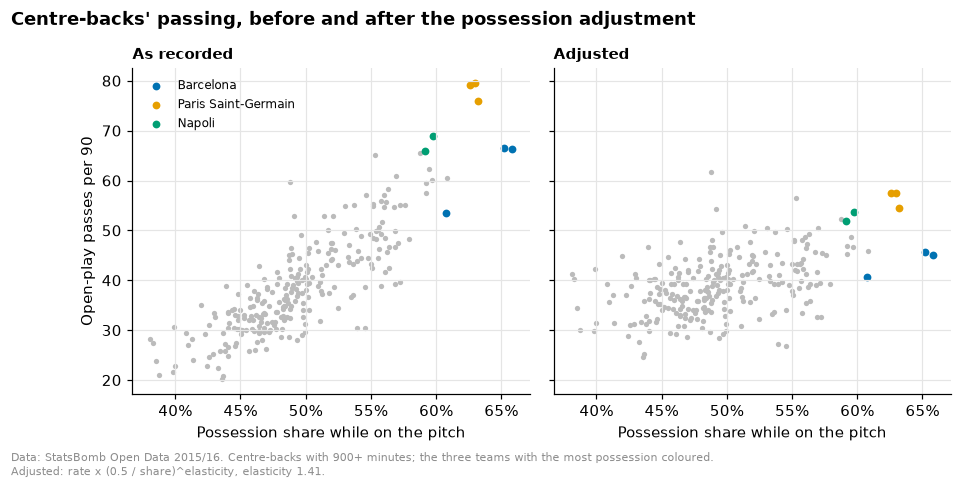

In [24]:
NAMES = (
    con.sql("SELECT player_id, coalesce(player_nickname, player_name) AS name FROM players")
    .df()
    .set_index("player_id")
    .name
)
cb = group.index[group == "CB"]
cb_rates = adjusted(reg_rates.loc[cb], share.loc[cb], "CB", "elasticity")
top_teams = team_season.share.nlargest(3).index
highlight = cb[main_team.loc[cb].isin(top_teams)]
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.0), sharex=True, sharey=True)
for ax, values, title in zip(
    axes, [reg_rates.loc[cb, "passes"], cb_rates.passes], ["As recorded", "Adjusted"], strict=True
):
    ax.scatter(share.loc[cb], values, s=12, color="#BBBBBB", lw=0)
    for team_id, colour in zip(top_teams, OKABE_ITO, strict=False):
        ids = highlight[main_team.loc[highlight] == team_id]
        ax.scatter(share.loc[ids], values.loc[ids], s=26, color=colour, lw=0,
                   label=TEAM_NAMES[team_id])  # fmt: skip
    ax.set_title(title, fontsize=10)
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_xlabel("Possession share while on the pitch")
    ax.grid(axis="x")
axes[0].set_ylabel("Open-play passes per 90")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Centre-backs' passing, before and after the possession adjustment",
             x=0.01, ha="left", fontweight="bold")  # fmt: skip
fig.subplots_adjust(top=0.85, wspace=0.06)
credit(fig, "Data: StatsBomb Open Data 2015/16. Centre-backs with 900+ minutes; the three "
       "teams with the most possession coloured.\nAdjusted: rate x (0.5 / share)^elasticity, "
       f"elasticity {BETA.loc['passes', 'CB']:.2f}.")  # fmt: skip
plt.show()

In [25]:
pd.DataFrame(
    {
        "team": main_team.loc[highlight].map(TEAM_NAMES),
        "possession": share.loc[highlight].map("{:.0%}".format),
        "passes per 90": reg_rates.loc[highlight, "passes"].round(1),
        "rank": reg_rates.loc[cb, "passes"].rank(ascending=False).loc[highlight].astype(int),
        "adjusted": cb_rates.loc[highlight, "passes"].round(1),
        "rank ": cb_rates.passes.rank(ascending=False).loc[highlight].astype(int),
    }
).set_axis(NAMES.loc[highlight]).rename_axis(f"Rank of {len(cb)} centre-backs")

,team,possession,passes per 90,rank,adjusted,rank
Rank of 261 centre-backs,,,,,,
Thiago Silva,Paris Saint-Germain,63%,79.1,2,57.5,2
David Luiz,Paris Saint-Germain,63%,76.0,3,54.6,5
Marquinhos,Paris Saint-Germain,63%,79.6,1,57.4,3
Gerard Piqué,Barcelona,65%,66.6,5,45.8,36
Javier Mascherano,Barcelona,66%,66.3,6,45.0,46
Kalidou Koulibaly,Napoli,60%,69.0,4,53.6,7
Raúl Albiol,Napoli,59%,65.8,7,51.9,9
Jérémy Mathieu,Barcelona,61%,53.5,30,40.7,98


In [26]:
order = compared[compared.adjustment == "elasticity"].set_index(["group", "metric"])
counted_order = order[order.side != "ratio"]
top20 = {}
for g in OUTFIELD:
    ids = group.index[group == g]
    values = adjusted(reg_rates.loc[ids], share.loc[ids], g, "elasticity")
    top20[g] = np.mean([
        len(set(values[m].nlargest(20).index) & set(reg_rates.loc[ids, m].nlargest(20).index))
        for m in PROFILES[g] if m in PER_90
    ])  # fmt: skip
lowest = counted_order["same order"].groupby(level="group").idxmin()
pd.DataFrame(
    {
        "same order (median Spearman)": counted_order.groupby(level="group")["same order"].median(),
        "lowest": counted_order.groupby(level="group")["same order"].min(),
        "for": lowest.map(lambda key: LABELS[key[1]]),
        "top 20 kept (mean)": pd.Series(top20),
    }
).loc[OUTFIELD].rename(index=GROUP_NAMES).round(2)

,same order (median Spearman),lowest,for,top 20 kept (mean)
Centre-backs,0.94,0.86,Open-play passes,14.50
Full-backs,0.97,0.87,Open-play passes,15.27
Central midfielders,0.97,0.88,Open-play passes,15.10
Attacking midfielders and wingers,0.98,0.96,Pressures,17.33
Centre-forwards,0.99,0.89,Touches in the opposition box,16.38


Paris Saint-Germain's centre-backs pass the most in the pool as recorded and stay in the top
five once possession is taken out; Piqué and Mascherano, at Barcelona, drop from 5th and 6th to
36th and 46th. Across groups, the adjustment keeps the recorded order closely: median Spearman 0.94 to
0.99, and 14 to 17 of each statistic's top 20 on average. It moves players at the ends of the
possession range, which is where it should.

### What section 2 shows

- **Possession**, as time with the ball, ranges from 39% (Carpi) to 65% (Barcelona) over the
  season, and from 22% to 78% in a match. It agrees with the share of passes (0.97).
- **Season figures** tie the statistics made with the ball to possession (open-play passes 0.74
  to 0.84 among defenders and central midfielders) and barely the defensive ones. Season
  figures cannot tell possession from the players a team with the ball can afford.
- **Within players**, counts with the ball grow faster than the team's time with it, except
  forwards'; counts without the ball grow more slowly than the opponent's time, and recoveries
  and centre-backs' aerial duels rise with the team's own possession.
- **Adjusting by the measured elasticity** takes possession out of both kinds without
  overshooting, and predicts the right size of change for players who changed teams. Adjusting in
  proportion to the time, and more so StatsBomb's PAdj, overshoots on defensive counts and
  ranks defenders by their team's possession.
- **The cost** is small: reliability falls by 0.05 or more for twelve statistic-group pairs,
  and below 0.4 for one, full-backs' key passes (0.35).
- **Not taken out**: the rest of the team's style. Passing volume still correlates with
  possession (0.35 to 0.49) and pass completion, left as recorded, depends on the team (team
  share 0.41 to 0.60 among defenders and central midfielders).